In [6]:
# Decision Tree Classifier – Pima Indians Diabetes Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
df = pd.read_csv("C:/Users/Ajsha/Downloads/archive/diabetes.csv")

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [8]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [9]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [10]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Independent Variables (X):")
print(X.columns.tolist())

print("\nDependent Variable (y):")
print(y.name)

Independent Variables (X):
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Dependent Variable (y):
Outcome


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X, y,test_size=0.20,random_state=42,stratify=y)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [13]:
from sklearn.tree import DecisionTreeClassifier

dt_entropy = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42,
    max_depth=4
)

dt_entropy.fit(X_train, y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [14]:
y_pred = dt_entropy.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
[1 0 0 1 0 0 0 1 0 1 0 0 0 0 0 1 1 0 1 0 0 1 0 1 1 0 1 0 1 0 0 0 0 0 0 0 0
 0 0 1 0 0 0 1 0 1 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 0 0 1 0 1 1 0 0 1 0 0 0 1
 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 1 1 0 1 1 0 0 0 0 0 1 0 1 0 1 0 0
 1 1 1 0 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 1 0]


In [15]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.8051948051948052
Accuracy Percentage: 80.51948051948052 %


In [16]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.87      0.85       100
           1       0.74      0.69      0.71        54

    accuracy                           0.81       154
   macro avg       0.79      0.78      0.78       154
weighted avg       0.80      0.81      0.80       154



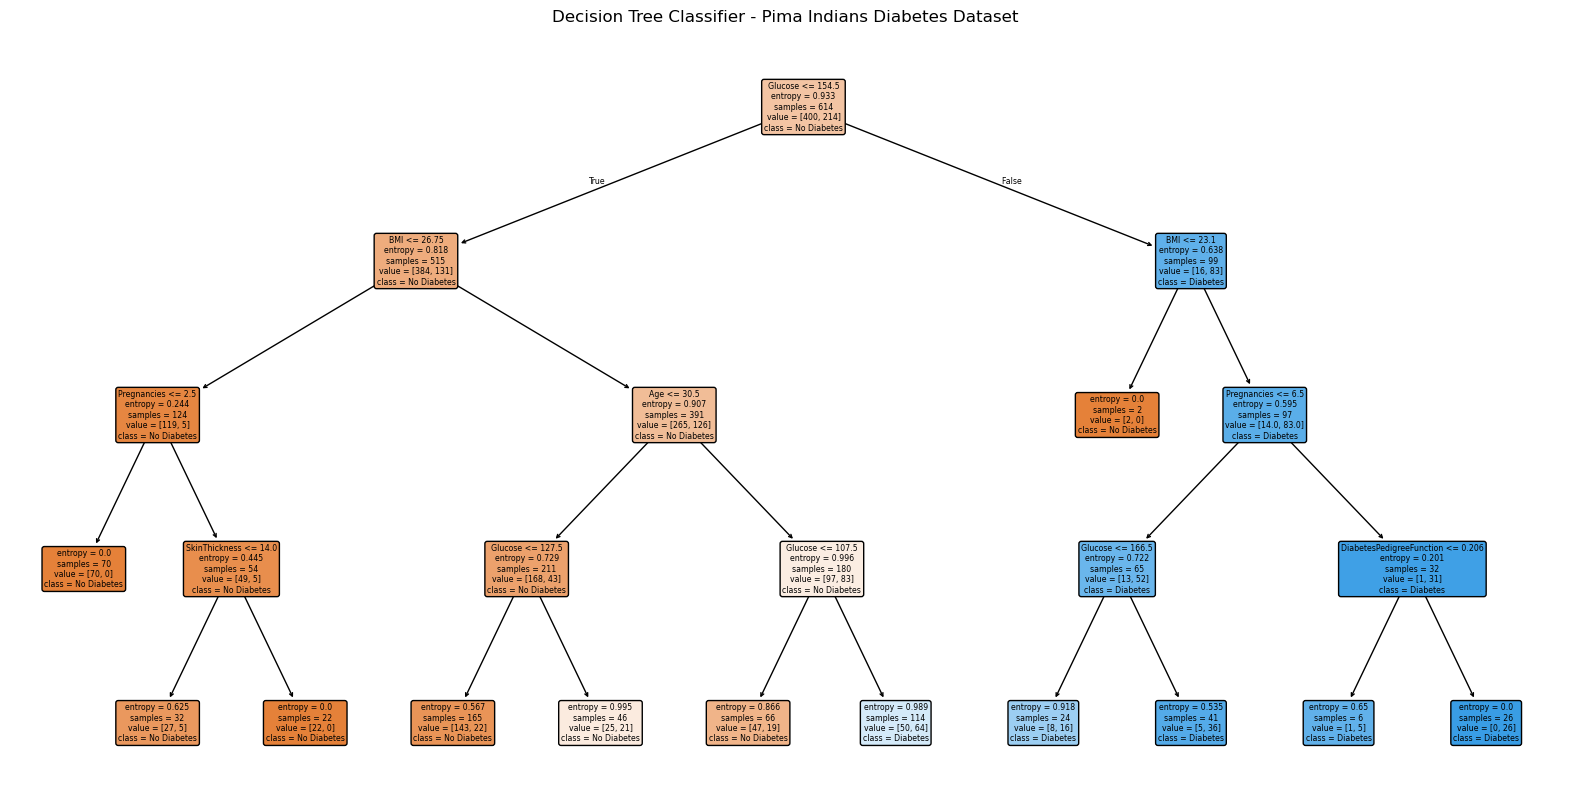

In [17]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    dt_entropy,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree Classifier - Pima Indians Diabetes Dataset")
plt.show()

In [18]:
root_index = dt_entropy.tree_.feature[0]
root_feature = X.columns[root_index]
root_threshold = dt_entropy.tree_.threshold[0]

print("Root Feature:", root_feature)
print("Root Threshold:", root_threshold)

Root Feature: Glucose
Root Threshold: 154.5


In [23]:
probabilities = y.value_counts(normalize=True)

entropy_value = -sum(
    p * np.log2(p)
    for p in probabilities
)

print("Entropy of Outcome:", entropy_value)

Entropy of Outcome: 0.9331343166407831


In [24]:
probabilities = y.value_counts(normalize=True)

gini_value = 1 - sum(
    p ** 2
    for p in probabilities
)

print("Gini Index of Outcome:", gini_value)

Gini Index of Outcome: 0.45437282986111116


In [25]:
def entropy(y):
    probabilities = y.value_counts(normalize=True)

    return -sum(
        p * np.log2(p)
        for p in probabilities
        if p > 0
    )


def information_gain(data, target, feature):

    parent_entropy = entropy(data[target])

    values = sorted(data[feature].unique())

    best_gain = -1
    best_threshold = None

    for i in range(len(values) - 1):

        threshold = (values[i] + values[i + 1]) / 2

        left = data[data[feature] <= threshold][target]
        right = data[data[feature] > threshold][target]

        if len(left) == 0 or len(right) == 0:
            continue

        weighted_entropy = (
            (len(left) / len(data)) * entropy(left)
            +
            (len(right) / len(data)) * entropy(right)
        )

        gain = parent_entropy - weighted_entropy

        if gain > best_gain:
            best_gain = gain
            best_threshold = threshold

    return best_gain, best_threshold

In [26]:
results = []

for feature in X.columns:

    gain, threshold = information_gain(
        df,
        "Outcome",
        feature
    )

    results.append([
        feature,
        gain,
        threshold
    ])

ig_df = pd.DataFrame(
    results,
    columns=[
        "Feature",
        "Information Gain",
        "Best Threshold"
    ]
)

ig_df = ig_df.sort_values(
    by="Information Gain",
    ascending=False
)

ig_df

,Feature,Information Gain,Best Threshold
1,Glucose,0.130810,127.5000
5,BMI,0.074899,27.8500
7,Age,0.072473,28.5000
0,Pregnancies,0.039180,6.5000
4,Insulin,0.026802,121.0000
6,DiabetesPedigreeFunction,0.020796,0.5275
3,SkinThickness,0.016903,31.5000
2,BloodPressure,0.014049,69.0000


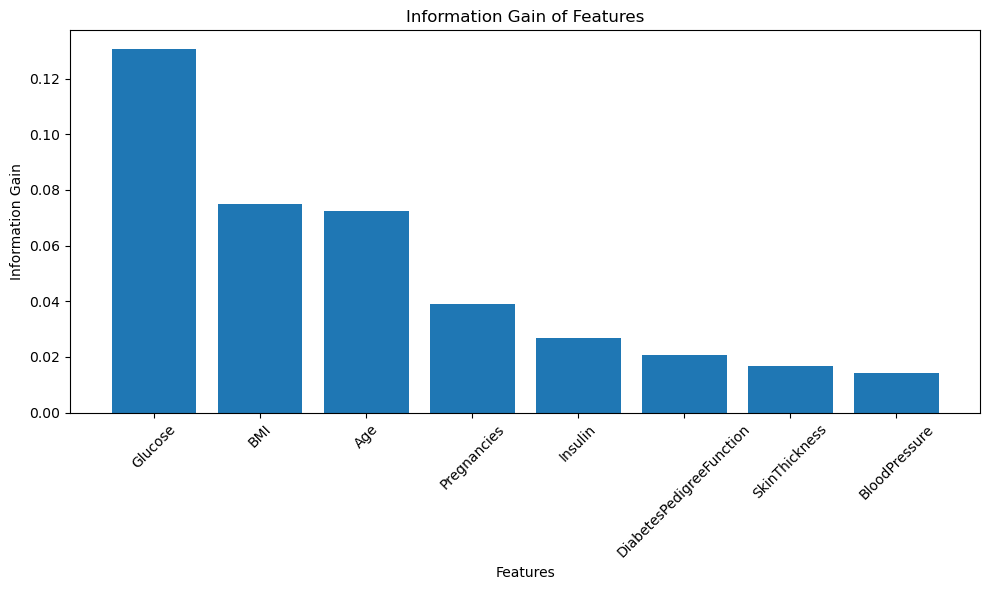

In [27]:
plt.figure(figsize=(10, 6))

plt.bar(
    ig_df["Feature"],
    ig_df["Information Gain"]
)

plt.xlabel("Features")
plt.ylabel("Information Gain")
plt.title("Information Gain of Features")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
def gini(y):
    p = y.value_counts(normalize=True)
    return 1 - sum(p**2)

def gini_gain(data, target, feature):
    parent = gini(data[target])
    values = sorted(data[feature].unique())
    
    best_gain = -1
    
    for i in range(len(values) - 1):
        threshold = (values[i] + values[i+1]) / 2
        
        left = data[data[feature] <= threshold][target]
        right = data[data[feature] > threshold][target]
        
        weighted = (
            len(left)/len(data) * gini(left) +
            len(right)/len(data) * gini(right)
        )
        
        gain = parent - weighted
        
        if gain > best_gain:
            best_gain = gain
    
    return best_gain

In [29]:
gini_results = []

for feature in X.columns:
    gain = gini_gain(df, "Outcome", feature)
    gini_results.append([feature, gain])

gini_df = pd.DataFrame(
    gini_results,
    columns=["Feature", "Gini Gain"]
).sort_values("Gini Gain", ascending=False)

gini_df

,Feature,Gini Gain
1,Glucose,0.082500
7,Age,0.044259
5,BMI,0.042870
0,Pregnancies,0.025642
4,Insulin,0.017369
6,DiabetesPedigreeFunction,0.013310
3,SkinThickness,0.010883
2,BloodPressure,0.008713


In [30]:
comparison = ig_df[["Feature", "Information Gain"]].merge(
    gini_df,
    on="Feature"
)

comparison.sort_values(
    "Information Gain",
    ascending=False
)

,Feature,Information Gain,Gini Gain
0,Glucose,0.130810,0.082500
1,BMI,0.074899,0.042870
2,Age,0.072473,0.044259
3,Pregnancies,0.039180,0.025642
4,Insulin,0.026802,0.017369
5,DiabetesPedigreeFunction,0.020796,0.013310
6,SkinThickness,0.016903,0.010883
7,BloodPressure,0.014049,0.008713
